<a href="https://colab.research.google.com/github/BioML-UGent/Advanced-AI-for-Bioinformatics/blob/main/06_VAEs/PClab_6_solved.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PC lab 6: Variational autoencoders (solutions)

The networks in PC labs 1-4 predicted a label from an input. A **variational autoencoder** (VAE) learns to generate new inputs. It encodes an image into a latent representation, then decodes that representation back into an image. We build a VAE for MNIST, generate new digits, and compare two ways of regularizing the latent space.

**Learning goals**
- Build an encoder and decoder in PyTorch
- Understand the reparameterization trick and the VAE loss
- Reconstruct images and generate new images from noise
- Visualize latent representations

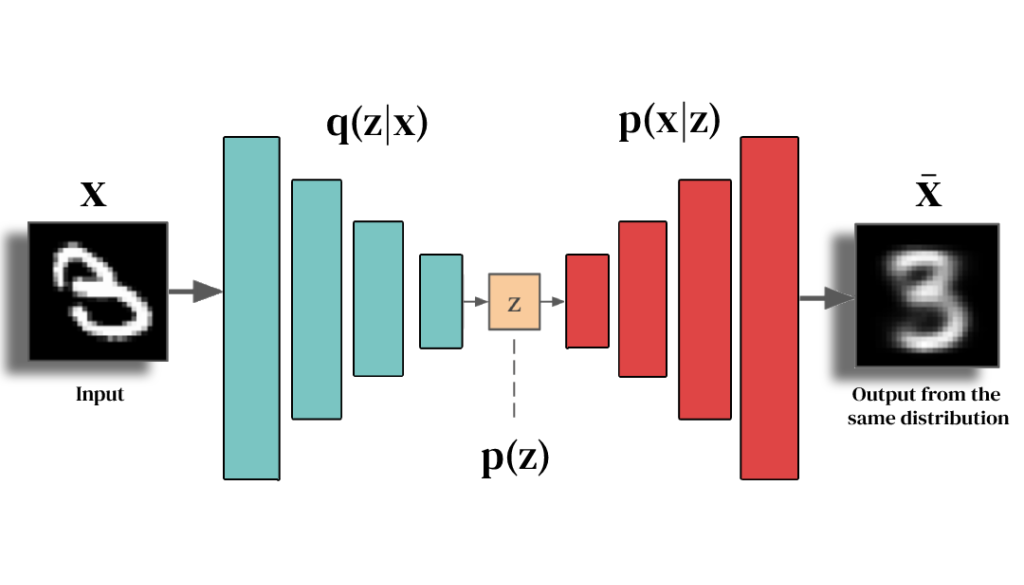


## 0 How does a VAE work?

The **encoder** takes an image $x$ and returns the parameters of a distribution over $z$: a mean $\mu$ and a log variance $\log\sigma^2$. We use a Gaussian with a diagonal covariance matrix, so every latent coordinate has its own variance:

$$q(z \mid x) = \mathcal{N}\big(\mu(x), \mathrm{diag}(\sigma^2(x))\big).$$

The **decoder** maps a latent vector $z$ to 784 pixel probabilities $\theta$. We use a standard normal **prior**, $p(z) = \mathcal{N}(0, I)$, and model each pixel as a Bernoulli variable:

$$z \sim \mathcal{N}(0, I), \qquad \theta = g(z), \qquad x_i \sim \mathrm{Bernoulli}(\theta_i).$$

During training, we sample from this distribution and try to reconstruct the input. The encoder predicts **log variance**, because it can take any real value; exponentiating it gives a positive variance.


In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets

torch.manual_seed(42)
np.random.seed(42)

## 1 Hyperparameters

Each MNIST image has 28 × 28 = 784 pixels. As in the MLP of PC lab 1, we flatten it to a vector.

In [2]:
batch_size = 100
x_dim = 784
hidden_dim = 400
latent_dim = 200
lr = 1e-3
n_epochs = 10

## 2 Loading MNIST

We use the same MNIST dataset as before. This time, we round the scaled pixel values to 0 or 1, to match the Bernoulli model. The labels are not used for training; we keep them to color the latent-space plots later. The test loader keeps the original order.


In [3]:
train_data = datasets.MNIST(root="data", train=True, download=True)
test_data = datasets.MNIST(root="data", train=False, download=True)

X_train = (train_data.data.float() / 255).round().reshape(-1, x_dim)
X_test = (test_data.data.float() / 255).round().reshape(-1, x_dim)
y_train, y_test = train_data.targets, test_data.targets

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=batch_size, shuffle=False)

X_batch, _ = next(iter(train_loader))
print(X_train.shape, X_test.shape)
print("one batch:", X_batch.shape)

torch.Size([60000, 784]) torch.Size([10000, 784])
one batch: torch.Size([100, 784])


## 3 Building the model

The encoder and decoder are ordinary MLPs, built with `nn.Linear` and `nn.Sequential`. The difference is that the encoder has **two output layers**: one for the mean and one for the log variance. The decoder ends with a sigmoid, so every pixel probability is between 0 and 1.


<div class="alert alert-success">

<b>EXERCISE 1: encoder and decoder</b>

a) Complete `Encoder`:
- `self.layers`: two linear layers, each followed by `nn.LeakyReLU()`,
- `self.mean` and `self.log_var`: separate linear layers.

b) Complete `Decoder`: three linear layers. Use `nn.LeakyReLU()` after the first two.

For a batch of $N$ images, the encoder outputs should both have shape `(N, latent_dim)` and the decoder output `(N, x_dim)`.

</div>

a)


In [4]:
class Encoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
        )
        self.mean = nn.Linear(hidden_dim, latent_dim)
        self.log_var = nn.Linear(hidden_dim, latent_dim)

    def forward(self, x):
        hidden = self.layers(x)
        return self.mean(hidden), self.log_var(hidden)


b)


In [5]:
class Decoder(nn.Module):
    def __init__(self, latent_dim, hidden_dim, output_dim):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, output_dim),
            nn.Sigmoid(),
        )

    def forward(self, z):
        return self.layers(z)


### The reparameterization trick

Sampling directly from $q(z \mid x)$ makes it difficult to backpropagate through the sample. Instead, we sample noise independently and write:

$$\epsilon \sim \mathcal{N}(0, I), \qquad z = \mu + \sigma \odot \epsilon.$$

Now the dependence on $\mu$ and $\sigma$ is an ordinary tensor operation. Since the encoder returns log variance, the standard deviation is $\sigma = \exp(0.5\log\sigma^2)$. The multiplication is element-wise.


<div class="alert alert-success">

<b>EXERCISE 2: reparameterization</b>

Complete `reparameterize`: compute the standard deviation, draw noise with `torch.randn_like(...)`, and return a sample `z` using the equation above.

</div>

In [6]:
class VAE(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def reparameterize(self, mean, log_var):
        std = torch.exp(0.5 * log_var)
        noise = torch.randn_like(mean)
        return mean + std * noise

    def forward(self, x):
        mean, log_var = self.encoder(x)
        z = self.reparameterize(mean, log_var)
        theta = self.decoder(z)
        return theta, mean, log_var, z


## 4 Initializing the model

We combine the encoder and decoder into a VAE. Check the output shapes. `theta` has one probability per pixel; the other outputs have one value per latent coordinate.

In [7]:
torch.manual_seed(0)
encoder = Encoder(x_dim, hidden_dim, latent_dim)
decoder = Decoder(latent_dim, hidden_dim, x_dim)
model = VAE(encoder, decoder)

theta, mean, log_var, z = model(X_batch)
print("pixels:", theta.shape)
print("mean, log variance, sample:", mean.shape, log_var.shape, z.shape)


pixels: torch.Size([100, 784])
mean, log variance, sample: torch.Size([100, 200]) torch.Size([100, 200]) torch.Size([100, 200])


## 5 Loss function and optimizer

We maximize the **evidence lower bound** (ELBO):

$$\mathrm{ELBO} = \mathbb{E}_{q(z \mid x)}[\log p(x \mid z)] - D_{\mathrm{KL}}\big(q(z \mid x)\,\|\,p(z)\big).$$

In code, we minimize its negative: **reconstruction loss + KL divergence**. The reconstruction term asks the decoder to reproduce the input. We approximate the expectation with one sampled `z` per image. For Bernoulli pixels, the negative log likelihood is the binary cross-entropy, summed over the pixels:

$$R(x, \theta) = -\sum_i \big[x_i\log\theta_i + (1-x_i)\log(1-\theta_i)\big].$$

The KL term pulls the encoder's distribution towards the standard normal prior. For our diagonal Gaussian, it has a closed form:

$$K(\mu, \log\sigma^2) = \frac{1}{2}\sum_j \big[\mu_j^2 + \exp(\log\sigma_j^2) - 1 - \log\sigma_j^2\big].$$

Both sums are **per image**. We average their total over the batch, so the reported loss does not depend on the batch size.


<div class="alert alert-success">

<b>EXERCISE 3: the VAE loss</b>

Complete `loss_function` using the two formulas above:
- use `F.binary_cross_entropy` with `reduction="..."`, for the reconstruction loss,
- sum the KL term over latent coordinates, then average over images.

Return the sum of the two terms. We use Adam with the learning rate defined in section 1.

</div>


In [8]:
def loss_function(x, theta, mean, log_var):
    reconstruction = F.binary_cross_entropy(theta, x, reduction="sum") / len(x)
    kl = 0.5 * (mean.pow(2) + log_var.exp() - 1 - log_var).sum(dim=1).mean()
    return reconstruction + kl


optimizer = torch.optim.Adam(model.parameters(), lr=lr)

## 6 Training the model

This is the same training loop as in PC lab 2. Here the target is the input image itself. The labels are ignored. The cell prints the average loss per image after every epoch.

In [9]:
for epoch in range(1, n_epochs + 1):
    model.train()
    total_loss = 0.0
    for X_batch, _ in train_loader:
        optimizer.zero_grad()
        theta, mean, log_var, z = model(X_batch)
        loss = loss_function(X_batch, theta, mean, log_var)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(X_batch)

    print(f"epoch {epoch}: training loss {total_loss / len(train_loader.dataset):.3f}")


epoch 1: training loss 170.007
epoch 2: training loss 119.096
epoch 3: training loss 104.517
epoch 4: training loss 97.741
epoch 5: training loss 93.784
epoch 6: training loss 91.418
epoch 7: training loss 89.564
epoch 8: training loss 88.165
epoch 9: training loss 87.086
epoch 10: training loss 86.178


## 7 Reconstructing test images

First, we encode a test image, sample a latent vector from its distribution, and decode it. This is a **reconstruction** of an existing image. We display the pixel probabilities `theta` as grayscale values; we could also sample binary pixels from them.


<div class="alert alert-success">

<b>EXERCISE 4: reconstructions</b>

a) Complete the loop below. Collect the reconstructions and the encoder **means** for the full test set. `torch.cat` joins the batches along the sample dimension.

b) Run the plotting cells to compare the first eight test images with their reconstructions. <b>THINK:</b> Which details are preserved, and which are lost?

We store the means for the later latent-space plot: unlike sampled vectors, they do not change each time we encode an image.

</div>

a)


In [10]:
model.eval()
z_test, reconstructions = [], []
with torch.no_grad():
    for X_batch, _ in test_loader:
        theta, mean, log_var, z = model(X_batch)
        z_test.append(mean)
        reconstructions.append(theta)

z_test = torch.cat(z_test, dim=0)
reconstructions = torch.cat(reconstructions, dim=0)
print(z_test.shape, reconstructions.shape)

torch.Size([10000, 200]) torch.Size([10000, 784])


b)


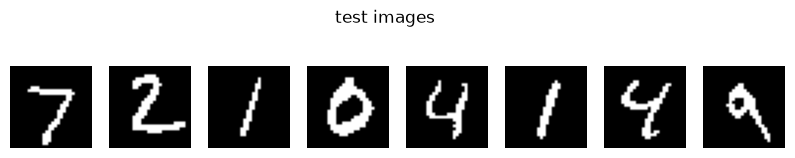

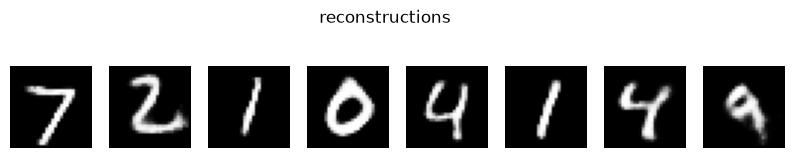

In [11]:
def show_images(images, title):
    fig, axes = plt.subplots(1, 8, figsize=(10, 2))
    for ax, image in zip(axes, images[:8]):
        ax.imshow(image.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    fig.suptitle(title)
    plt.show()


show_images(X_test, "test images")
show_images(reconstructions, "reconstructions")


**Answer:**

The overall digit shape and thick strokes are usually preserved. Fine edges, small gaps and stroke thickness can be blurred or changed. The decoder displays pixel probabilities, so uncertain pixels appear gray rather than sharply black or white.


## 8 Generating images from noise

To generate a new image, we do not need an input or the encoder. We draw $z$ from the prior $\mathcal{N}(0, I)$ and pass it directly to the decoder. The KL term encouraged the latent distributions seen during training to stay close to this prior.


<div class="alert alert-success">

<b>EXERCISE 5: new images</b>

Draw a batch of latent vectors with `torch.randn`, of shape `(batch_size, ...)`, and pass them to `model.decoder`. Display the generated images with `show_images`. Run the cell a few times. Do all samples look like recognizable digits?

</div>


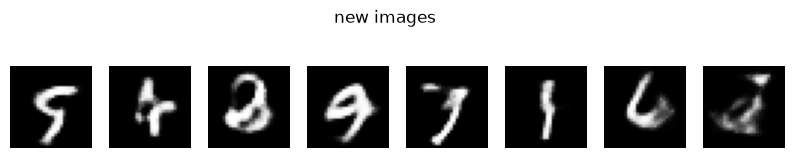

In [30]:
model.eval()
with torch.no_grad():
    z = torch.randn(batch_size, latent_dim)
    generated_images = model.decoder(z)

show_images(generated_images, "new images")


**Answer:**

Many samples should resemble digits, but some may be ambiguous or poorly formed. Matching the latent distributions to the prior is only approximate, and the decoder does not learn every region of the prior equally well. Each run of this cell draws different latent vectors.


## 9 Visualizing the latent representations

A VAE can also provide features for downstream tasks. We use t-SNE to project the encoder means of the first 200 test images from 200 dimensions to 2D. Each point is an image, colored by its digit label. These labels were never shown to the VAE during training.

t-SNE emphasizes local neighborhoods. Its axes have no direct meaning, and distances between separate groups should not be interpreted as distances in the original latent space.


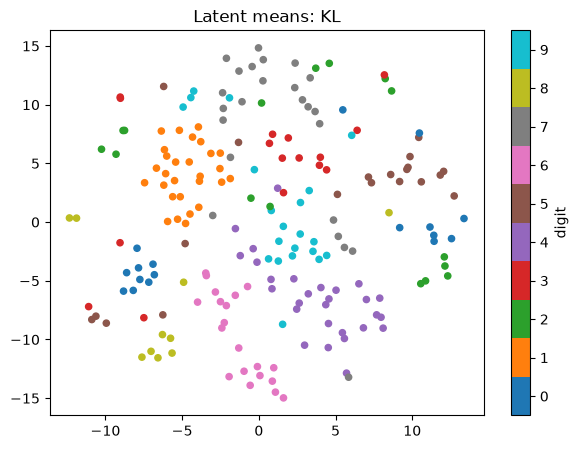

In [13]:
from sklearn.manifold import TSNE

rep_2d = TSNE(n_components=2, random_state=0).fit_transform(z_test[:200].numpy())

plt.figure(figsize=(7, 5))
plt.scatter(rep_2d[:, 0], rep_2d[:, 1], c=y_test[:200], cmap="tab10", s=20, vmin=-0.5, vmax=9.5)
plt.colorbar(ticks=range(10), label="digit")
plt.title("Latent means: KL")
plt.show()


<div class="alert alert-success">

<b>EXERCISE 6 (THINK): the latent space</b>

a) Do images of the same digit tend to be neighbors? Which digits overlap?

b) The network was trained without labels. Why might it still put similar digits near each other? How could these representations be used in a downstream task?

</div>


**Answer:**

a) Similar digits often form local groups, with overlap between similar shapes, such as 4 and 9 or 3 and 5. The exact groups depend on training and the t-SNE projection.

b) To reconstruct images, the encoder must retain features such as strokes, loops and orientation. Images with similar features can therefore have similar representations even without labels. These features can be used for clustering or as inputs to a classifier.


## 10 Latent representations with MMD

The KL term regularizes the distribution of **every image** towards the prior. An alternative is **maximum mean discrepancy** (MMD): compare the distribution of latent samples from all images with samples from the prior. This can leave more freedom for individual images to have different representations.

With a kernel $k$, the squared MMD is:

$$\mathrm{MMD}^2(p, q) = \mathbb{E}_{p,p}[k(z,z')] + \mathbb{E}_{q,q}[k(z,z')] - 2\mathbb{E}_{p,q}[k(z,z')].$$

We approximate each expectation by the mean over **all pairs** in a batch. The RBF kernel below returns a matrix of shape `(len(x1), len(x2))`, with one similarity per pair. It averages squared differences over latent coordinates to keep the scale manageable.


In [14]:
def compute_rbf(x1, x2):
    differences = x1[:, None, :] - x2[None, :, :]
    return torch.exp(-differences.pow(2).mean(dim=2) / 2)


print(compute_rbf(torch.randn(5, latent_dim), torch.randn(8, latent_dim)).shape)


torch.Size([5, 8])


<div class="alert alert-success">

<b>EXERCISE 7: MMD</b>

Complete `MMD` using `compute_rbf`. Compute the prior–prior, latent–latent and prior–latent kernel matrices, take their means, and combine them using the equation above. Here we include the diagonal entries in the means.

</div>


In [15]:
def MMD(prior_z, z):
    prior_prior = compute_rbf(prior_z, prior_z).mean()
    latent_latent = compute_rbf(z, z).mean()
    prior_latent = compute_rbf(prior_z, z).mean()
    return prior_prior + latent_latent - 2 * prior_latent


<div class="alert alert-success">

<b>EXERCISE 8: reconstruction loss + MMD</b>

Complete `loss_mmd`: use the same reconstruction loss as in Exercise 3, draw prior samples with `torch.randn_like(z)`, and add `beta * MMD(prior_z, z)`. `beta` controls the strength of the penalty; start with 1.

Then run the cells below to train a new model with the same architecture and initial weights, using this loss.

</div>


In [16]:
def loss_mmd(x, theta, z, beta=1):
    reconstruction = F.binary_cross_entropy(theta, x, reduction="sum") / len(x)
    prior_z = torch.randn_like(z)
    mmd = MMD(prior_z, z)
    return reconstruction + beta * mmd


In [17]:
torch.manual_seed(0)
encoder_2 = Encoder(x_dim, hidden_dim, latent_dim)
decoder_2 = Decoder(latent_dim, hidden_dim, x_dim)
model_2 = VAE(encoder_2, decoder_2)
optimizer_2 = torch.optim.Adam(model_2.parameters(), lr=lr)


In [18]:
for epoch in range(1, n_epochs + 1):
    model_2.train()
    total_loss = 0.0
    for X_batch, _ in train_loader:
        optimizer_2.zero_grad()
        theta, mean, log_var, z = model_2(X_batch)
        loss = loss_mmd(X_batch, theta, z, beta=1)
        loss.backward()
        optimizer_2.step()
        total_loss += loss.item() * len(X_batch)

    print(f"epoch {epoch}: training loss {total_loss / len(train_loader.dataset):.3f}")


epoch 1: training loss 121.586
epoch 2: training loss 58.070
epoch 3: training loss 44.883
epoch 4: training loss 38.679
epoch 5: training loss 34.492
epoch 6: training loss 31.441
epoch 7: training loss 29.161
epoch 8: training loss 27.344
epoch 9: training loss 25.801
epoch 10: training loss 24.424


<div class="alert alert-success">

<b>EXERCISE 9: representations from the MMD model</b>

Complete the encoder call below and collect the means for the test set, as in Exercise 4. Run the next cell to project and plot the same 200 images, using the same t-SNE settings. This lets us compare the two models using the same type of latent representation.

</div>


In [19]:
model_2.eval()
z_test_mmd = []
with torch.no_grad():
    for X_batch, _ in test_loader:
        mean, log_var = model_2.encoder(X_batch)
        z_test_mmd.append(mean)

z_test_mmd = torch.cat(z_test_mmd, dim=0)
print(z_test_mmd.shape)


torch.Size([10000, 200])


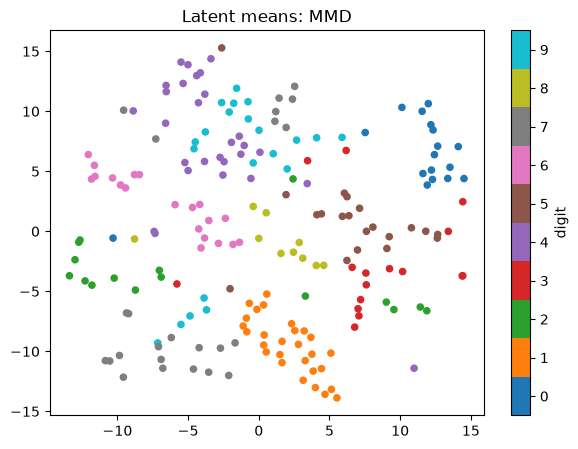

In [20]:
rep_2d_mmd = TSNE(n_components=2, random_state=0).fit_transform(z_test_mmd[:200].numpy())

plt.figure(figsize=(7, 5))
plt.scatter(rep_2d_mmd[:, 0], rep_2d_mmd[:, 1], c=y_test[:200], cmap="tab10", s=20, vmin=-0.5, vmax=9.5)
plt.colorbar(ticks=range(10), label="digit")
plt.title("Latent means: MMD")
plt.show()


<div class="alert alert-success">

<b>EXERCISE 10 (THINK): KL vs MMD</b>

a) Compare the two plots. Which digits form clearer groups, and which overlap? Relate any differences to what the two penalties regularize.

b) Does a clearer t-SNE plot prove that the representations are more useful? What additional check could you use, for example a classifier trained on the latent vectors?

c) Give a concrete downstream task where a more informative representation would help, such as grouping cell profiles or classifying images with few labels. Why might MMD be useful there?

</div>


**Answer:**

a) MMD can allow clearer digit groups because it matches the overall latent distribution, while KL pulls each image's distribution towards the prior. Better separation is not guaranteed: check which digits cluster or overlap in your two plots. The penalty strength and training also affect the result.

b) No. t-SNE changes the geometry and only shows a small subset of images. Train the same simple classifier on each model's **training-set** encoder means, and evaluate on held-out images, using the original latent dimensions rather than the 2D projection.

c) For classifying cell types from expression profiles with few labels, informative latent features can help a small classifier. MMD may preserve more differences between profiles while regularizing their overall distribution. Its usefulness should be checked on the downstream task.
